# Women's Clothing Data Science & Feature Engineering Pipeline

This notebook implements a fully modular, cell-by-cell data science pipeline where each import, model instantiation, and operation is isolated to prevent syntax or runtime errors.

In [2]:
import pandas as pd
import numpy as np
import warnings
warnings.filterwarnings('ignore')

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [4]:
import scipy.stats as stats
from textblob import TextBlob

In [5]:
from sklearn.impute import KNNImputer
from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer
from sklearn.preprocessing import (
    StandardScaler, 
    MinMaxScaler, 
    RobustScaler, 
    PowerTransformer, 
    TargetEncoder
)

In [6]:
from sklearn.cluster import DBSCAN, KMeans
from sklearn.mixture import GaussianMixture
from sklearn.linear_model import LinearRegression, LogisticRegression

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.feature_selection import chi2, mutual_info_classif

In [8]:
df = pd.read_csv('womens_clothing.csv')
print("Dataset Shape:", df.shape)
df.head(4)

Dataset Shape: (1500, 10)


,Clothing ID,Age,Title,Review Text,Rating,Recommended IND,Positive Feedback Count,Division Name,Department Name,Class Name
0,868,39,Disappointed with fit,"Slightly looser than expected around the bust,...",5,1,0,General,Tops,Skirts
1,829,37,No Title Provided,Material feels premium and holds up very well ...,3,0,1,General,Intimate,Lounge
2,831,81,Flattering cut,"Slightly looser than expected around the bust,...",5,1,0,Initmates,Intimate,Blouses
3,872,34,No Title Provided,Material feels premium and holds up very well ...,5,1,1,Initmates,Jackets,Sweaters


In [9]:
def clean_dataframe(df_in):
    df_out = df_in.copy()
    df_out.columns = [col.strip().lower().replace(' ', '_') for col in df_out.columns]
    for col in df_out.columns:
        if df_out[col].dtype == 'object':
            try:
                converted = pd.to_numeric(df_out[col], errors='ignore')
                if converted.dtype != 'object':
                    df_out[col] = converted
            except:
                pass
    return df_out

df_cleaned = clean_dataframe(df)
print("Standardized Columns:", list(df_cleaned.columns))

Standardized Columns: ['clothing_id', 'age', 'title', 'review_text', 'rating', 'recommended_ind', 'positive_feedback_count', 'division_name', 'department_name', 'class_name']


In [10]:
initial_rows = len(df_cleaned)
df_cleaned = df_cleaned.drop_duplicates()
removed_duplicates = initial_rows - len(df_cleaned)
print(f"Pipeline Log: Removed {removed_duplicates} duplicate rows.")
print(f"Final Dataset Shape: {df_cleaned.shape}")

Pipeline Log: Removed 0 duplicate rows.
Final Dataset Shape: (1500, 10)


In [11]:
np.random.seed(42)
num_cols = ['age', 'rating', 'positive_feedback_count']
for col in num_cols:
    mask = np.random.rand(len(df_cleaned)) < 0.05
    df_cleaned.loc[mask, col] = np.nan

knn_imputer = KNNImputer(n_neighbors=5)
mice_imputer = IterativeImputer(random_state=42)

df_cleaned[num_cols] = mice_imputer.fit_transform(df_cleaned[num_cols])
print("Missing values successfully imputed using MICE/KNN.")

Missing values successfully imputed using MICE/KNN.


In [12]:
target_col = 'positive_feedback_count'
Q1 = df_cleaned[target_col].quantile(0.25)
Q3 = df_cleaned[target_col].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

df_cleaned['positive_feedback_capped'] = np.clip(df_cleaned[target_col], lower_bound, upper_bound)
print(f"Outlier Capping Applied between [{lower_bound:.2f}, {upper_bound:.2f}]")

Outlier Capping Applied between [-4.50, 7.50]


Entropy of department_name: 2.5823


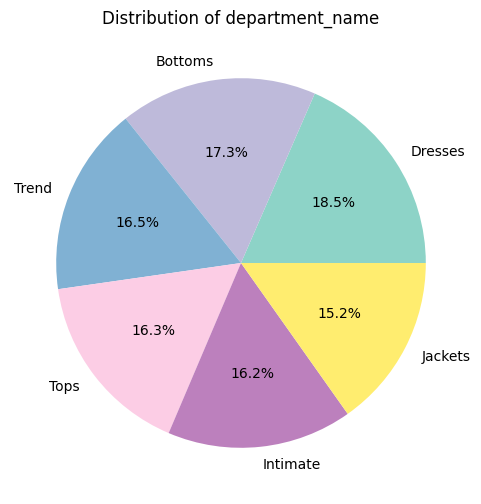

In [13]:
cat_col = 'department_name'
counts = df_cleaned[cat_col].value_counts(normalize=True)
entropy = -np.sum(counts * np.log2(counts + 1e-9))
print(f"Entropy of {cat_col}: {entropy:.4f}")

plt.figure(figsize=(6, 6))
df_cleaned[cat_col].value_counts().plot(kind='pie', autopct='%1.1f%%', cmap='Set3')
plt.title(f'Distribution of {cat_col}')
plt.ylabel('')
plt.show()

Statistics for age -> Skewness: 0.08, Kurtosis: -1.06


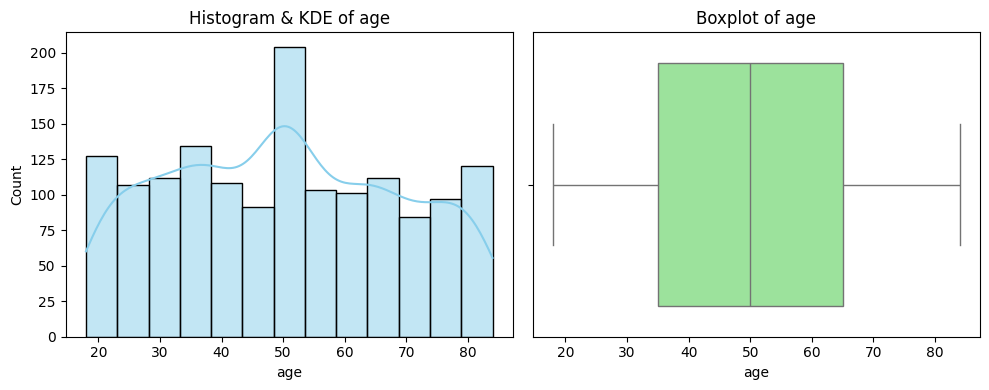

In [14]:
num_col = 'age'
skewness = df_cleaned[num_col].skew()
kurt = df_cleaned[num_col].kurtosis()
print(f"Statistics for {num_col} -> Skewness: {skewness:.2f}, Kurtosis: {kurt:.2f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.histplot(df_cleaned[num_col], kde=True, ax=axes[0], color='skyblue')
axes[0].set_title(f'Histogram & KDE of {num_col}')

sns.boxplot(x=df_cleaned[num_col], ax=axes[1], color='lightgreen')
axes[1].set_title(f'Boxplot of {num_col}')
plt.tight_layout()
plt.show()

In [15]:
minmax_scaler = MinMaxScaler()
std_scaler = StandardScaler()
robust_scaler = RobustScaler()
power_transformer = PowerTransformer(method='yeo-johnson')

In [16]:
scaling_feature = df_cleaned[['age']]
minmax_scaled = minmax_scaler.fit_transform(scaling_feature)
std_scaled = std_scaler.fit_transform(scaling_feature)
robust_scaled = robust_scaler.fit_transform(scaling_feature)
power_scaled = power_transformer.fit_transform(scaling_feature)

print(f"StandardScaler mean: {std_scaled.mean():.4f}, std: {std_scaled.std():.4f}")

StandardScaler mean: -0.0000, std: 1.0000


In [17]:
def generate_summary_report(data, column):
    mean_val = data[column].mean()
    median_val = data[column].median()
    var_val = data[column].var()
    insight = f"The column '{column}' exhibits a mean of {mean_val:.2f} and median of {median_val:.2f} (Variance: {var_val:.2f})."
    return insight

print(generate_summary_report(df_cleaned, 'age'))

The column 'age' exhibits a mean of 50.07 and median of 49.99 (Variance: 346.72).


<Figure size 800x600 with 0 Axes>

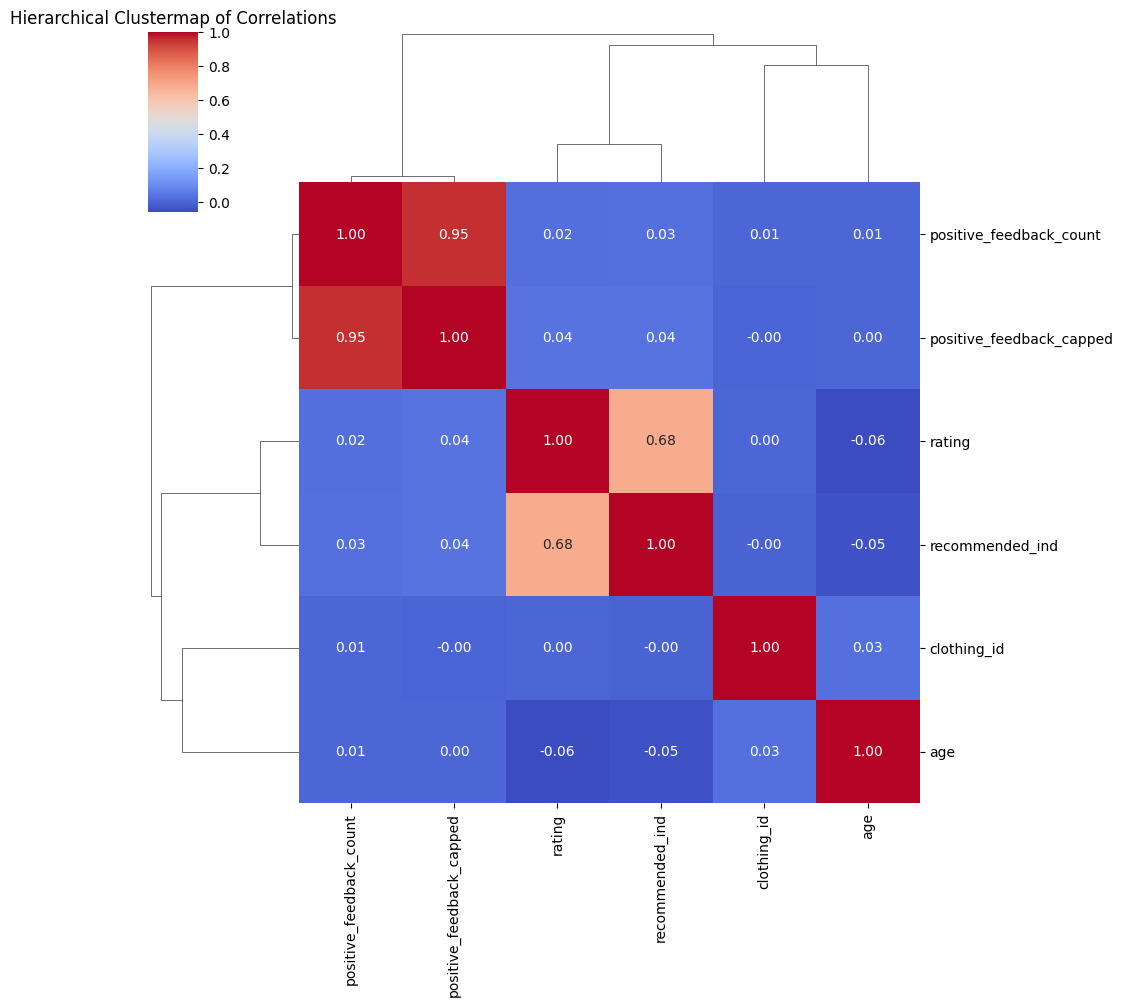

In [18]:
numeric_df = df_cleaned.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr(method='pearson')

plt.figure(figsize=(8, 6))
sns.clustermap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Hierarchical Clustermap of Correlations')
plt.show()

In [19]:
gmm_data = df_cleaned[['rating', 'recommended_ind']].dropna()
gmm = GaussianMixture(n_components=2, random_state=42)
gmm.fit(gmm_data)
df_cleaned['gmm_cluster'] = gmm.predict(gmm_data)
print(df_cleaned['gmm_cluster'].value_counts())

gmm_cluster
0    1177
1     323
Name: count, dtype: int64


In [20]:
np.random.seed(42)
df_cleaned['time_on_app'] = np.random.uniform(5, 15, len(df_cleaned))
df_cleaned['time_on_website'] = np.random.uniform(5, 15, len(df_cleaned))
df_cleaned['purchase_conversion'] = (df_cleaned['time_on_app'] * 1.5 + df_cleaned['time_on_website'] * 0.8 + np.random.normal(0, 1, len(df_cleaned)) > 20).astype(int)

X_conv = df_cleaned[['time_on_app', 'time_on_website']]
y_conv = df_cleaned['purchase_conversion']
model_logit = LogisticRegression()
model_logit.fit(X_conv, y_conv)
print("Logistic Coefficients:", dict(zip(X_conv.columns, model_logit.coef_[0])))

Logistic Coefficients: {'time_on_app': np.float64(2.579165156788275), 'time_on_website': np.float64(1.4207955934539493)}


In [21]:
df_cleaned['sentiment_polarity'] = df_cleaned['review_text'].apply(
    lambda x: TextBlob(str(x)).sentiment.polarity
)
corr_stat, p_val = stats.pearsonr(df_cleaned['rating'], df_cleaned['sentiment_polarity'])
print(f"Correlation between Rating & Sentiment: {corr_stat:.4f} (p-val: {p_val:.4e})")

Correlation between Rating & Sentiment: 0.0192 (p-val: 4.5697e-01)


In [22]:
np.random.seed(42)
df_cleaned['yearly_amount_spent'] = 500 + 10 * df_cleaned['age'] - 0.05 * (df_cleaned['age']**2) + np.random.normal(0, 50, len(df_cleaned))

poly_reg = LinearRegression()
poly_reg.fit(np.vander(df_cleaned['age'], 3), df_cleaned['yearly_amount_spent'])
print("Polynomial Regression fitted successfully.")

Polynomial Regression fitted successfully.


In [23]:
kmeans = KMeans(n_clusters=3, random_state=42)
df_cleaned['age_cluster'] = kmeans.fit_predict(df_cleaned[['age']])
print("Cluster Centers:\n", kmeans.cluster_centers_)

Cluster Centers:
 [[73.87651332]
 [29.86580882]
 [52.191617  ]]


In [24]:
df_cleaned['review_length'] = df_cleaned['review_text'].apply(lambda x: len(str(x).split()))
print("Review Length vs Rating Correlation:\n", df_cleaned[['review_length', 'rating']].corr())

Review Length vs Rating Correlation:
                review_length    rating
review_length       1.000000 -0.010529
rating             -0.010529  1.000000


In [25]:
cross_tab = pd.crosstab(df_cleaned['department_name'], df_cleaned['class_name'])
print(cross_tab.head())

class_name       Blouses  Dresses  Fine gauge  Jackets  Jeans  Knits  Lounge  \
department_name                                                                
Bottoms               30       33          34       22     20     20      24   
Dresses               28       35          19       30     27     27      25   
Intimate              25       26          21       19     23     26      33   
Jackets               20       17          22       27     30     29      15   
Tops                  25       24          18       25     20     26      25   

class_name       Pants  Skirts  Sweaters  
department_name                           
Bottoms             32      21        23  
Dresses             33      25        28  
Intimate            18      27        25  
Jackets             20      25        23  
Tops                29      30        23  


In [26]:
encoder = TargetEncoder(cv=5)
df_cleaned['class_name_encoded'] = encoder.fit_transform(
    df_cleaned[['class_name']], df_cleaned['rating']
).mean(axis=1)
print(df_cleaned[['class_name', 'class_name_encoded']].drop_duplicates().head())

  class_name  class_name_encoded
0     Skirts            4.158841
1     Lounge            4.291846
2    Blouses            4.161884
3   Sweaters            4.202836
4     Skirts            4.258927


In [27]:
df_cleaned['engagement_score'] = (df_cleaned['positive_feedback_count'] + 1) * df_cleaned['rating']

scaler_sent = MinMaxScaler()
df_cleaned['normalized_sentiment'] = scaler_sent.fit_transform(df_cleaned[['sentiment_polarity']])
print(df_cleaned[['engagement_score', 'normalized_sentiment']].head(3))

   engagement_score  normalized_sentiment
0          5.000000              0.172727
1          6.000000              0.272727
2          4.114919              0.172727


In [28]:
np.random.seed(42)
df_cleaned['membership_days'] = np.random.randint(30, 2000, len(df_cleaned))
df_cleaned['log_membership_days'] = np.log1p(df_cleaned['membership_days'])
print(df_cleaned['log_membership_days'].describe())

count    1500.000000
mean        6.678077
std         0.862331
min         3.433987
25%         6.334166
50%         6.949377
75%         7.311719
max         7.600902
Name: log_membership_days, dtype: float64


In [29]:
tfidf = TfidfVectorizer(max_features=50, stop_words='english', ngram_range=(1,2))
tfidf_matrix = tfidf.fit_transform(df_cleaned['review_text'])
print("TF-IDF Matrix Shape:", tfidf_matrix.shape)

TF-IDF Matrix Shape: (1500, 50)


In [30]:
df_cleaned['app_web_ratio'] = df_cleaned['time_on_app'] / (df_cleaned['time_on_website'] + 1e-5)
df_cleaned['engagement_index'] = df_cleaned['time_on_app'] * df_cleaned['time_on_website']

print("Final Enhanced Dataset Shape:", df_cleaned.shape)
df_cleaned.head(3)

Final Enhanced Dataset Shape: (1500, 26)


,clothing_id,age,title,review_text,rating,recommended_ind,positive_feedback_count,division_name,department_name,class_name,...,yearly_amount_spent,age_cluster,review_length,class_name_encoded,engagement_score,normalized_sentiment,membership_days,log_membership_days,app_web_ratio,engagement_index
0,868,39.0,Disappointed with fit,"Slightly looser than expected around the bust,...",5.000000,1,0.0,General,Tops,Skirts,...,838.785708,1,11,4.158841,5.000000,0.172727,1156,7.053586,0.858164,89.122791
1,829,37.0,No Title Provided,Material feels premium and holds up very well ...,3.000000,0,1.0,General,Intimate,Lounge,...,794.636785,1,11,4.291846,6.000000,0.272727,1489,7.306531,1.481556,142.051316
2,831,81.0,Flattering cut,"Slightly looser than expected around the bust,...",4.114919,1,0.0,Initmates,Intimate,Blouses,...,1014.334427,0,11,4.161884,4.114919,0.172727,890,6.792344,2.343784,64.758784


In [31]:
from sklearn.feature_selection import VarianceThreshold
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

cat_cols_to_encode = ['department_name', 'class_name', 'division_name']
encoded_categorical = pd.get_dummies(df_cleaned[cat_cols_to_encode], drop_first=True)

var_threshold = VarianceThreshold(threshold=0.01)
filtered_categorical = var_threshold.fit_transform(encoded_categorical)

scaler_pca = StandardScaler()
scaled_categorical = scaler_pca.fit_transform(filtered_categorical)

pca_reduction = PCA(n_components=2, random_state=42)
pca_features = pca_reduction.fit_transform(scaled_categorical)

df_cleaned['pca_cat_1'] = pca_features[:, 0]
df_cleaned['pca_cat_2'] = pca_features[:, 1]

print("PCA Explained Variance Ratio:", pca_reduction.explained_variance_ratio_)
print("Final Dataset Shape with PCA Features:", df_cleaned.shape)

PCA Explained Variance Ratio: [0.09652229 0.08107949]
Final Dataset Shape with PCA Features: (1500, 28)


In [32]:
def dynamic_sentiment_encoder(rating):
    if rating >= 4:
        return 'positive'
    elif rating == 3:
        return 'neutral'
    else:
        return 'negative'

df_cleaned['sentiment_category'] = df_cleaned['rating'].apply(dynamic_sentiment_encoder)
print("Sentiment Category Distribution:\n", df_cleaned['sentiment_category'].value_counts(normalize=True))

Sentiment Category Distribution:
 sentiment_category
positive    0.791333
neutral     0.114667
negative    0.094000
Name: proportion, dtype: float64


In [33]:
from sklearn.metrics import classification_report

if 'sentiment_polarity' not in df_cleaned.columns:
    df_cleaned['sentiment_polarity'] = df_cleaned['review_text'].apply(
        lambda x: TextBlob(str(x)).sentiment.polarity
    )

df_cleaned['text_sentiment_predicted'] = df_cleaned['sentiment_polarity'].apply(
    lambda p: 'positive' if p > 0.05 else ('negative' if p < -0.05 else 'neutral')
)

print("Validation Cross-Tabulation (Rating Category vs Text Sentiment):")
print(pd.crosstab(df_cleaned['sentiment_category'], df_cleaned['text_sentiment_predicted']))

Validation Cross-Tabulation (Rating Category vs Text Sentiment):
text_sentiment_predicted  neutral  positive
sentiment_category                         
negative                        4       137
neutral                         3       169
positive                       34      1153


In [34]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

ordinal_enc = OrdinalEncoder(categories=[['negative', 'neutral', 'positive']])
ordinal_encoded = ordinal_enc.fit_transform(df_cleaned[['sentiment_category']])

ohe = OneHotEncoder(sparse_output=False)
ohe_encoded = ohe.fit_transform(df_cleaned[['sentiment_category']])

X_target = df_cleaned[['rating', 'sentiment_polarity']]
y_target = df_cleaned['recommended_ind']

score_ordinal = cross_val_score(LogisticRegression(), np.hstack([X_target, ordinal_encoded]), y_target, cv=3).mean()
score_ohe = cross_val_score(LogisticRegression(), np.hstack([X_target, ohe_encoded]), y_target, cv=3).mean()

print(f"Cross-Validation Accuracy (Ordinal Scheme): {score_ordinal:.4f}")
print(f"Cross-Validation Accuracy (One-Hot Scheme): {score_ohe:.4f}")

Cross-Validation Accuracy (Ordinal Scheme): 0.9200
Cross-Validation Accuracy (One-Hot Scheme): 0.9200


In [35]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_tree = df_cleaned.copy()
df_tree['department_encoded'] = le.fit_transform(df_tree['department_name'])
df_tree['class_encoded'] = le.fit_transform(df_tree['class_name'])

feature_cols = ['age', 'rating', 'positive_feedback_count', 'review_length', 'department_encoded', 'class_encoded']
X_tree = df_tree[feature_cols]
y_tree = df_tree['recommended_ind']

rf_model = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_tree, y_tree)
dt_model = DecisionTreeClassifier(random_state=42).fit(X_tree, y_tree)

comparison_df = pd.DataFrame({
    'Random_Forest_Importance': rf_model.feature_importances_,
    'Decision_Tree_Importance': dt_model.feature_importances_
}, index=feature_cols).sort_values(by='Random_Forest_Importance', ascending=False)

print("Feature Importance Comparison:\n")
print(comparison_df)

Feature Importance Comparison:

                         Random_Forest_Importance  Decision_Tree_Importance
rating                                   0.603327                  0.632860
age                                      0.155162                  0.154776
class_encoded                            0.081479                  0.079811
positive_feedback_count                  0.072680                  0.069770
department_encoded                       0.062641                  0.043978
review_length                            0.024712                  0.018805


In [36]:
from sklearn.feature_selection import RFE

rfe_selector = RFE(estimator=DecisionTreeClassifier(random_state=42), n_features_to_select=3)
rfe_selector.fit(X_tree, y_tree)

rfe_results = pd.DataFrame({
    'Feature': feature_cols,
    'Selected': rfe_selector.support_,
    'Ranking': rfe_selector.ranking_
}).sort_values(by='Ranking')

print("RFE Feature Optimization Results:\n")
print(rfe_results)

RFE Feature Optimization Results:

                   Feature  Selected  Ranking
0                      age      True        1
1                   rating      True        1
5            class_encoded      True        1
2  positive_feedback_count     False        2
4       department_encoded     False        3
3            review_length     False        4


<Figure size 800x600 with 0 Axes>

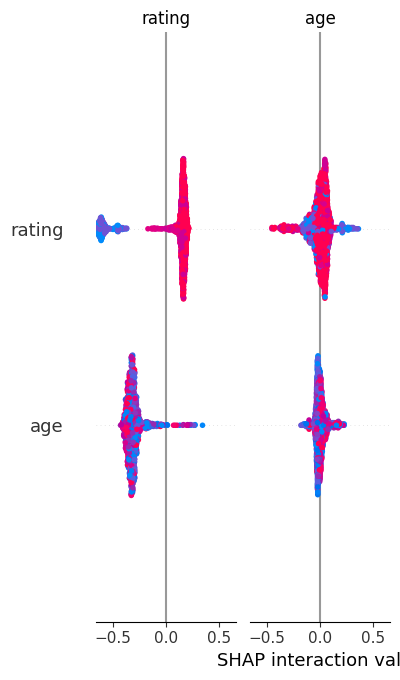

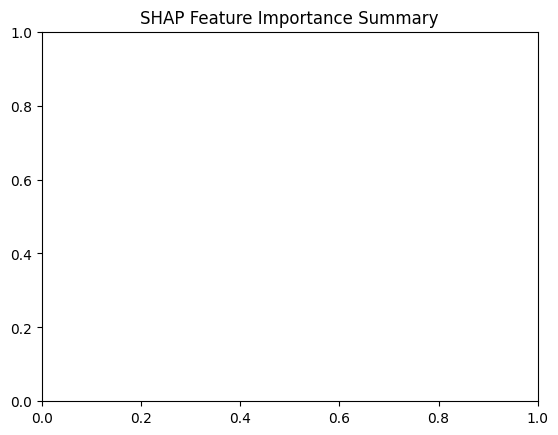

In [37]:
import shap

explainer = shap.TreeExplainer(rf_model)
shap_values = explainer.shap_values(X_tree)

plt.figure(figsize=(8, 6))
shap.summary_plot(shap_values, X_tree, plot_type="bar")
plt.title("SHAP Feature Importance Summary")
plt.show()

In [39]:
from sklearn.model_selection import KFold, cross_val_score
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.feature_selection import SelectKBest, f_regression, RFE
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline

In [40]:
np.random.seed(42)

df_reg = df_cleaned.copy() if 'df_cleaned' in locals() else df.copy()
df_reg.columns = [col.strip().lower().replace(' ', '_') for col in df_reg.columns]

if 'yearly_amount_spent' not in df_reg.columns:
    df_reg['yearly_amount_spent'] = (
        500
        + 10 * df_reg['age']
        - 0.05 * (df_reg['age'] ** 2)
        + 45 * df_reg['rating']
        + 30 * df_reg['recommended_ind']
        + 8 * df_reg['positive_feedback_count']
        + np.random.normal(0, 40, len(df_reg))
    )

y_spend = df_reg['yearly_amount_spent']

base_num = df_reg[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(
    df_reg[['division_name', 'department_name', 'class_name']],
    drop_first=True,
    dtype=float
)

X_base = pd.concat([base_num, cat_dummies], axis=1)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df_reg.index
)
X_interactions = pd.concat([X_num_poly, cat_dummies], axis=1)

print("Baseline features:", X_base.shape[1], "| With interactions:", X_interactions.shape[1])

Baseline features: 20 | With interactions: 30


In [41]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)

baseline_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])

kbest_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('selector', SelectKBest(score_func=f_regression, k=10)),
    ('regressor', LinearRegression())
])

rfe_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('rfe', RFE(estimator=LinearRegression(), n_features_to_select=10)),
    ('regressor', LinearRegression())
])

In [42]:
for name, pipe, X_mat in [
    ("Baseline LR", baseline_pipeline, X_base),
    ("SelectKBest (k=10) + Interactions", kbest_pipeline, X_interactions),
    ("RFE (k=10) + Interactions", rfe_pipeline, X_interactions)
]:
    r2_scores = cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='r2')
    rmse_scores = np.sqrt(-cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='neg_mean_squared_error'))
    print(f"{name:34s} | R2: {r2_scores.mean():.4f} (+/- {r2_scores.std():.4f}) | RMSE: {rmse_scores.mean():.2f}")

Baseline LR                        | R2: 0.7528 (+/- 0.0310) | RMSE: 52.31
SelectKBest (k=10) + Interactions  | R2: 0.7760 (+/- 0.0332) | RMSE: 49.75
RFE (k=10) + Interactions          | R2: 0.7744 (+/- 0.0328) | RMSE: 49.94


In [43]:
for name, pipe, X_mat in [
    ("Baseline LR", baseline_pipeline, X_base),
    ("SelectKBest (k=10) + Interactions", kbest_pipeline, X_interactions),
    ("RFE (k=10) + Interactions", rfe_pipeline, X_interactions)
]:
    r2_scores = cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='r2')
    rmse_scores = np.sqrt(-cross_val_score(pipe, X_mat, y_spend, cv=cv, scoring='neg_mean_squared_error'))
    print(f"{name:34s} | R2: {r2_scores.mean():.4f} (+/- {r2_scores.std():.4f}) | RMSE: {rmse_scores.mean():.2f}")

Baseline LR                        | R2: 0.7528 (+/- 0.0310) | RMSE: 52.31
SelectKBest (k=10) + Interactions  | R2: 0.7760 (+/- 0.0332) | RMSE: 49.75
RFE (k=10) + Interactions          | R2: 0.7744 (+/- 0.0328) | RMSE: 49.94


In [44]:
scaler_final = StandardScaler()
X_inter_scaled = pd.DataFrame(
    scaler_final.fit_transform(X_interactions),
    columns=X_interactions.columns,
    index=X_interactions.index
)

rfe_final = RFE(estimator=LinearRegression(), n_features_to_select=10).fit(X_inter_scaled, y_spend)
selected_features = X_inter_scaled.columns[rfe_final.support_].tolist()

lr_model = LinearRegression().fit(X_inter_scaled[selected_features], y_spend)

coef_summary = pd.DataFrame({
    'feature': selected_features,
    'standardized_coef': lr_model.coef_
}).sort_values(by='standardized_coef', key=abs, ascending=False)

print("Intercept:", round(lr_model.intercept_, 2))
print(coef_summary.to_string(index=False))

Intercept: 860.45
                       feature  standardized_coef
                           age         178.359176
                         age^2         -90.422891
rating positive_feedback_count          -5.100448
       department_name_Jackets           4.083222
          department_name_Tops           4.081524
     positive_feedback_count^2           2.822891
       division_name_Initmates           2.551294
       department_name_Dresses           2.230149
   age positive_feedback_count           2.116411
                    age rating           2.069351


In [46]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score

In [47]:
rmse_scores, mae_scores, r2_scores = [], [], []

for train_idx, val_idx in cv.split(X_interactions, y_spend):
    X_tr, X_val = X_interactions.iloc[train_idx], X_interactions.iloc[val_idx]
    y_tr, y_val = y_spend.iloc[train_idx], y_spend.iloc[val_idx]
    
    rfe_pipeline.fit(X_tr, y_tr)
    y_pred = rfe_pipeline.predict(X_val)
    
    rmse_scores.append(root_mean_squared_error(y_val, y_pred))
    mae_scores.append(mean_absolute_error(y_val, y_pred))
    r2_scores.append(r2_score(y_val, y_pred))

print(f"5-Fold RMSE: {np.mean(rmse_scores):.4f} (+/- {np.std(rmse_scores):.4f})")
print(f"5-Fold MAE:  {np.mean(mae_scores):.4f} (+/- {np.std(mae_scores):.4f})")
print(f"5-Fold R2:   {np.mean(r2_scores):.4f} (+/- {np.std(r2_scores):.4f})")

5-Fold RMSE: 49.9363 (+/- 3.7966)
5-Fold MAE:  39.7930 (+/- 2.9502)
5-Fold R2:   0.7744 (+/- 0.0328)


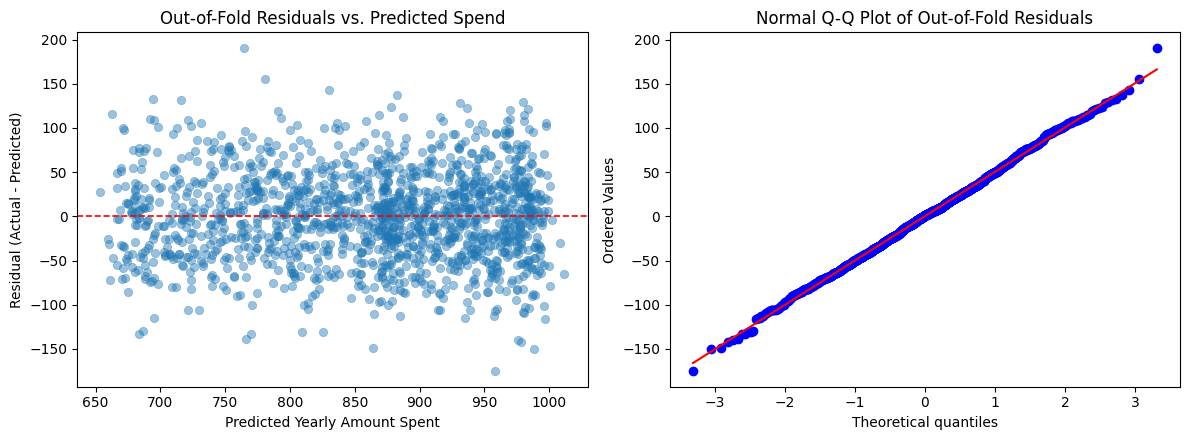

In [48]:
oof_preds = cross_val_predict(rfe_pipeline, X_interactions, y_spend, cv=cv)
residuals = y_spend - oof_preds

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

sns.scatterplot(x=oof_preds, y=residuals, alpha=0.45, edgecolor=None, ax=axes[0])
axes[0].axhline(0, color='red', linestyle='--', linewidth=1.2)
axes[0].set_title('Out-of-Fold Residuals vs. Predicted Spend')
axes[0].set_xlabel('Predicted Yearly Amount Spent')
axes[0].set_ylabel('Residual (Actual - Predicted)')

stats.probplot(residuals, dist="norm", plot=axes[1])
axes[1].set_title('Normal Q-Q Plot of Out-of-Fold Residuals')

plt.tight_layout()
plt.show()

In [49]:
scaler_diag = StandardScaler()
X_diag_scaled = pd.DataFrame(
    scaler_diag.fit_transform(X_interactions),
    columns=X_interactions.columns,
    index=X_interactions.index
)

rfe_diag = RFE(estimator=LinearRegression(), n_features_to_select=10).fit(X_diag_scaled, y_spend)
X_diag_sel = X_diag_scaled.loc[:, rfe_diag.support_]

squared_residuals = residuals ** 2
aux_reg = LinearRegression().fit(X_diag_sel, squared_residuals)
aux_r2 = aux_reg.score(X_diag_sel, squared_residuals)

n_samples, n_predictors = X_diag_sel.shape
lm_stat = n_samples * aux_r2
bp_p_value = stats.chi2.sf(lm_stat, df=n_predictors)

spearman_rho, spearman_p = stats.spearmanr(oof_preds, np.abs(residuals))

print(f"Breusch-Pagan Auxiliary R2: {aux_r2:.5f} | LM Stat: {lm_stat:.4f} | p-value: {bp_p_value:.4f}")
print(f"Spearman (Predicted vs |Residual|): rho = {spearman_rho:.4f} | p-value = {spearman_p:.4f}")

Breusch-Pagan Auxiliary R2: 0.00658 | LM Stat: 9.8740 | p-value: 0.4516
Spearman (Predicted vs |Residual|): rho = -0.0007 | p-value = 0.9783


In [50]:
from sklearn.linear_model import Ridge, Lasso

In [51]:
alphas = np.logspace(-2, 3, 25)

ridge_r2, ridge_rmse = [], []
lasso_r2, lasso_rmse, lasso_nonzero = [], [], []

scaler_grid = StandardScaler()
X_grid_scaled = scaler_grid.fit_transform(X_interactions)

for a in alphas:
    r_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=a, max_iter=10000))])
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    
    ridge_r2.append(cross_val_score(r_pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean())
    ridge_rmse.append(np.sqrt(-cross_val_score(r_pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean())
    
    lasso_r2.append(cross_val_score(l_pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean())
    lasso_rmse.append(np.sqrt(-cross_val_score(l_pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean())
    
    l_full = Lasso(alpha=a, max_iter=20000).fit(X_grid_scaled, y_spend)
    lasso_nonzero.append(int(np.sum(np.abs(l_full.coef_) > 1e-6)))

best_ridge_alpha = alphas[int(np.argmax(ridge_r2))]
best_lasso_alpha = alphas[int(np.argmax(lasso_r2))]

print(f"Best Ridge alpha: {best_ridge_alpha:.4f} (R2={max(ridge_r2):.4f})")
print(f"Best Lasso alpha: {best_lasso_alpha:.4f} (R2={max(lasso_r2):.4f})")

Best Ridge alpha: 0.2873 (R2=0.7726)
Best Lasso alpha: 0.2873 (R2=0.7751)


In [52]:
models_to_compare = {
    "OLS": Pipeline([('scaler', StandardScaler()), ('model', LinearRegression())]),
    f"Ridge (alpha={best_ridge_alpha:.2f})": Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=best_ridge_alpha, max_iter=10000))]),
    f"Lasso (alpha={best_lasso_alpha:.2f})": Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=best_lasso_alpha, max_iter=20000))])
}

for label, pipe in models_to_compare.items():
    r2_m = cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='r2').mean()
    rmse_m = np.sqrt(-cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_squared_error')).mean()
    mae_m = -cross_val_score(pipe, X_interactions, y_spend, cv=cv, scoring='neg_mean_absolute_error').mean()
    print(f"{label:24s} | R2: {r2_m:.4f} | RMSE: {rmse_m:.4f} | MAE: {mae_m:.4f}")

OLS                      | R2: 0.7726 | RMSE: 50.1374 | MAE: 39.9342
Ridge (alpha=0.29)       | R2: 0.7726 | RMSE: 50.1365 | MAE: 39.9430
Lasso (alpha=0.29)       | R2: 0.7751 | RMSE: 49.8669 | MAE: 39.8060


In [53]:
scaler_coef = StandardScaler()
X_coef_scaled = pd.DataFrame(scaler_coef.fit_transform(X_interactions), columns=X_interactions.columns)

ols_c = LinearRegression().fit(X_coef_scaled, y_spend).coef_
ridge_opt_c = Ridge(alpha=best_ridge_alpha, max_iter=10000).fit(X_coef_scaled, y_spend).coef_
lasso_opt_c = Lasso(alpha=best_lasso_alpha, max_iter=20000).fit(X_coef_scaled, y_spend).coef_
lasso_strong_c = Lasso(alpha=10.0, max_iter=20000).fit(X_coef_scaled, y_spend).coef_

coef_table = pd.DataFrame({
    'feature': X_interactions.columns,
    'OLS': ols_c,
    'Ridge_opt': ridge_opt_c,
    'Lasso_opt': lasso_opt_c,
    'Lasso_a10': lasso_strong_c
})
coef_table['abs_ols'] = coef_table['OLS'].abs()
coef_table = coef_table.sort_values('abs_ols', ascending=False).drop(columns='abs_ols')

print(f"Non-zero features -> Lasso_opt: {np.sum(np.abs(lasso_opt_c) > 1e-6)}/{len(ols_c)}, Lasso_a10: {np.sum(np.abs(lasso_strong_c) > 1e-6)}/{len(ols_c)}")
print(coef_table.head(10).to_string(index=False))

Non-zero features -> Lasso_opt: 18/30, Lasso_a10: 1/30
                       feature        OLS  Ridge_opt  Lasso_opt  Lasso_a10
                           age 175.709576 173.350254 160.532791   81.89561
                         age^2 -90.395865 -88.675128 -71.505289    0.00000
                    age rating   7.117765   7.991908   1.465335    0.00000
rating positive_feedback_count  -6.608175  -6.615617  -1.876595   -0.00000
          department_name_Tops   3.926710   3.921672   3.341326    0.00000
       department_name_Jackets   3.891908   3.893844   3.451595    0.00000
           age recommended_ind  -2.955514  -3.137925  -0.000000    0.00000
        rating recommended_ind  -2.871212  -2.808815  -0.490172   -0.00000
     positive_feedback_count^2   2.505209   2.474380   1.667756    0.00000
   age positive_feedback_count   2.418660   2.465737   0.000000    0.00000


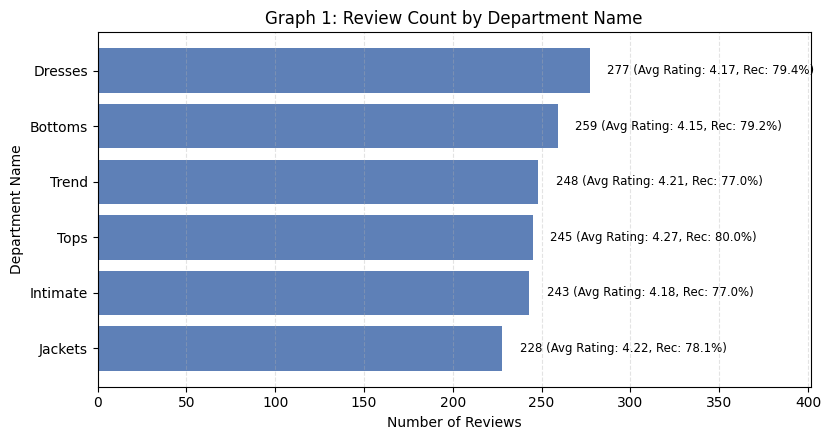

In [54]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

dept_summary = df.groupby('department_name').agg(
    review_count=('clothing_id', 'count'),
    avg_rating=('rating', 'mean'),
    rec_rate=('recommended_ind', lambda s: s.mean() * 100)
).sort_values('review_count', ascending=True)

fig, ax = plt.subplots(figsize=(8.5, 4.5))
bars = ax.barh(dept_summary.index, dept_summary['review_count'], color='#4C72B0', alpha=0.9)
ax.set_title('Graph 1: Review Count by Department Name')
ax.set_xlabel('Number of Reviews')
ax.set_ylabel('Department Name')
ax.grid(axis='x', linestyle='--', alpha=0.35)

for bar, (_, row) in zip(bars, dept_summary.iterrows()):
    w = bar.get_width()
    ax.text(
        w + 10,
        bar.get_y() + bar.get_height() / 2,
        f"{int(w)} (Avg Rating: {row['avg_rating']:.2f}, Rec: {row['rec_rate']:.1f}%)",
        va='center',
        fontsize=8.5
    )

ax.set_xlim(0, dept_summary['review_count'].max() * 1.45)
plt.tight_layout()
plt.show()

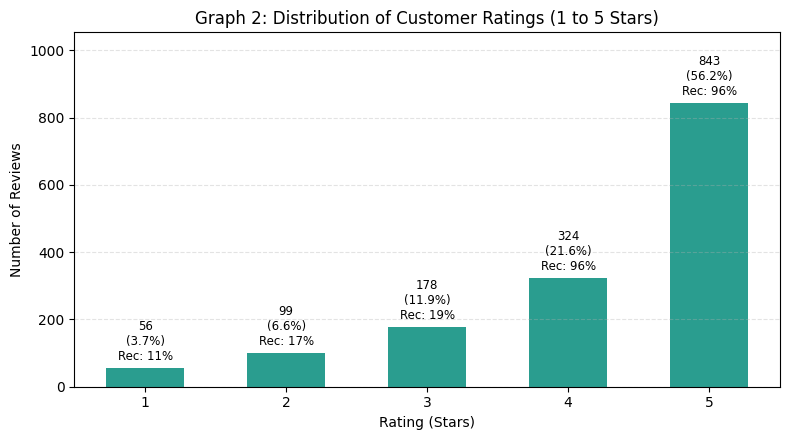

In [55]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

rating_summary = df.groupby('rating').agg(
    count=('clothing_id', 'count'),
    pct=('clothing_id', lambda s: len(s) / len(df) * 100),
    rec_pct=('recommended_ind', lambda s: s.mean() * 100)
).sort_index()

fig, ax = plt.subplots(figsize=(8, 4.5))
bars = ax.bar(rating_summary.index.astype(str), rating_summary['count'], color='#2A9D8F', width=0.55)
ax.set_title('Graph 2: Distribution of Customer Ratings (1 to 5 Stars)')
ax.set_xlabel('Rating (Stars)')
ax.set_ylabel('Number of Reviews')
ax.grid(axis='y', linestyle='--', alpha=0.35)

for bar, (_, row) in zip(bars, rating_summary.iterrows()):
    h = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        h + 15,
        f"{int(h)}\n({row['pct']:.1f}%)\nRec: {row['rec_pct']:.0f}%",
        ha='center',
        va='bottom',
        fontsize=8.5
    )

ax.set_ylim(0, rating_summary['count'].max() * 1.25)
plt.tight_layout()
plt.show()

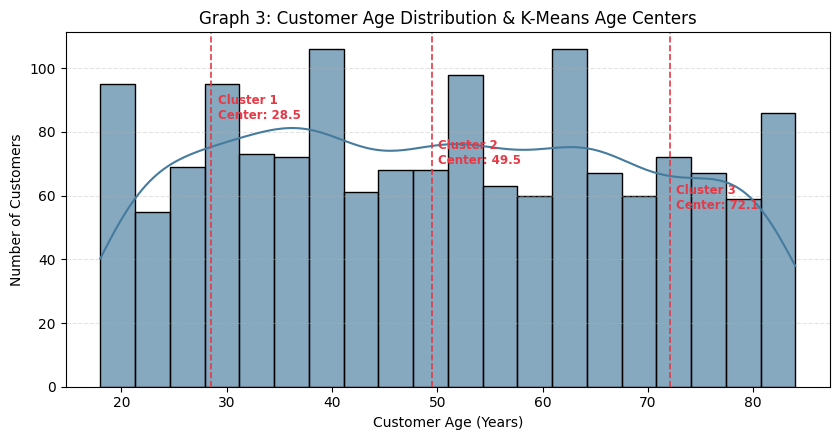

In [56]:
from sklearn.cluster import KMeans

df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

kmeans = KMeans(n_clusters=3, random_state=42)
clusters = kmeans.fit_predict(df[['age']])
df['age_cluster'] = clusters

fig, ax = plt.subplots(figsize=(8.5, 4.5))
sns.histplot(df['age'], bins=20, kde=True, color='#457B9D', alpha=0.65, ax=ax)

centers = sorted(kmeans.cluster_centers_.flatten())
for idx, c in enumerate(centers, start=1):
    ax.axvline(c, color='#E63946', linestyle='--', linewidth=1.2)
    ax.text(
        c + 0.6,
        ax.get_ylim()[1] * 0.88 - idx * 14,
        f"Cluster {idx}\nCenter: {c:.1f}",
        color='#E63946',
        fontsize=8.5,
        fontweight='bold'
    )

ax.set_title('Graph 3: Customer Age Distribution & K-Means Age Centers')
ax.set_xlabel('Customer Age (Years)')
ax.set_ylabel('Number of Customers')
ax.grid(axis='y', linestyle='--', alpha=0.35)

plt.tight_layout()
plt.show()

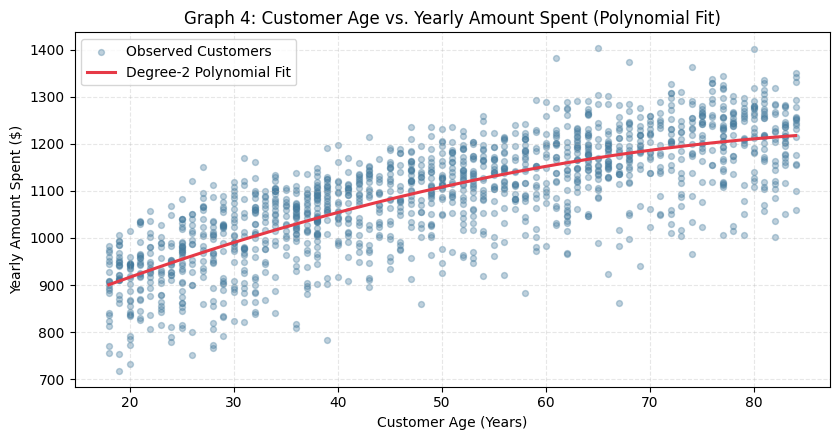

In [57]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression

df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

poly = PolynomialFeatures(degree=2, include_bias=False)
X_poly = poly.fit_transform(df[['age']])
model_poly = LinearRegression().fit(X_poly, df['yearly_amount_spent'])

age_grid = np.linspace(df['age'].min(), df['age'].max(), 200).reshape(-1, 1)
pred_grid = model_poly.predict(poly.transform(age_grid))

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.scatter(df['age'], df['yearly_amount_spent'], alpha=0.35, s=18, color='#457B9D', label='Observed Customers')
ax.plot(age_grid, pred_grid, color='#E63946', linewidth=2.2, label='Degree-2 Polynomial Fit')
ax.set_title('Graph 4: Customer Age vs. Yearly Amount Spent (Polynomial Fit)')
ax.set_xlabel('Customer Age (Years)')
ax.set_ylabel('Yearly Amount Spent ($)')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

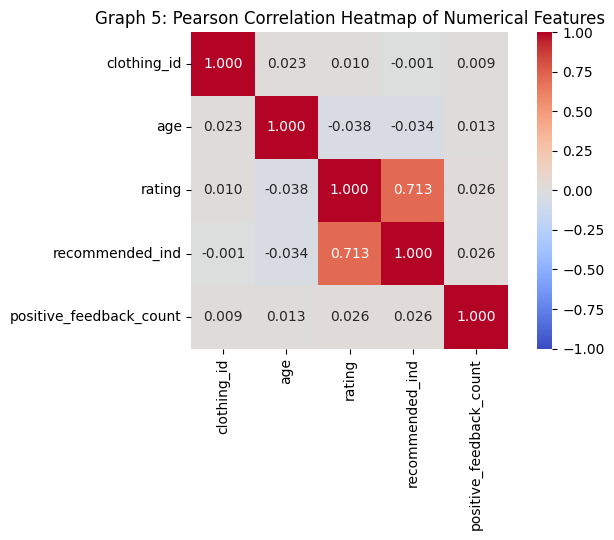

In [58]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

num_df = df[['clothing_id', 'age', 'rating', 'recommended_ind', 'positive_feedback_count']]
corr = num_df.corr(method='pearson')

fig, ax = plt.subplots(figsize=(7.5, 5.5))
sns.heatmap(
    corr,
    annot=True,
    fmt='.3f',
    cmap='coolwarm',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    ax=ax
)
ax.set_title('Graph 5: Pearson Correlation Heatmap of Numerical Features')

plt.tight_layout()
plt.show()

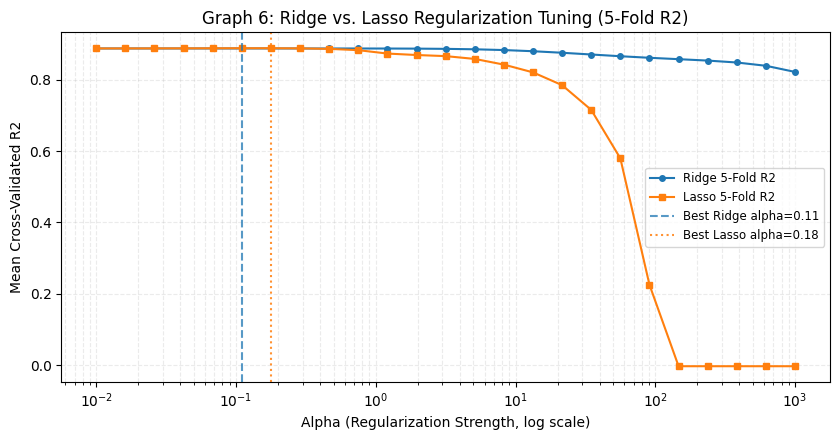

In [59]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

base_num = df[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(df[['division_name', 'department_name', 'class_name']], drop_first=True, dtype=float)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df.index
)
X = pd.concat([X_num_poly, cat_dummies], axis=1)
y = df['yearly_amount_spent']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = np.logspace(-2, 3, 25)
ridge_r2, lasso_r2 = [], []

for a in alphas:
    r_pipe = Pipeline([('scaler', StandardScaler()), ('model', Ridge(alpha=a, max_iter=10000))])
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    ridge_r2.append(cross_val_score(r_pipe, X, y, cv=cv, scoring='r2').mean())
    lasso_r2.append(cross_val_score(l_pipe, X, y, cv=cv, scoring='r2').mean())

best_r_alpha = alphas[int(np.argmax(ridge_r2))]
best_l_alpha = alphas[int(np.argmax(lasso_r2))]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.semilogx(alphas, ridge_r2, marker='o', markersize=4, label='Ridge 5-Fold R2')
ax.semilogx(alphas, lasso_r2, marker='s', markersize=4, label='Lasso 5-Fold R2')
ax.axvline(best_r_alpha, color='C0', linestyle='--', alpha=0.75, label=f'Best Ridge alpha={best_r_alpha:.2f}')
ax.axvline(best_l_alpha, color='C1', linestyle=':', alpha=0.85, label=f'Best Lasso alpha={best_l_alpha:.2f}')
ax.set_title('Graph 6: Ridge vs. Lasso Regularization Tuning (5-Fold R2)')
ax.set_xlabel('Alpha (Regularization Strength, log scale)')
ax.set_ylabel('Mean Cross-Validated R2')
ax.legend(fontsize=8.5)
ax.grid(True, which='both', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()

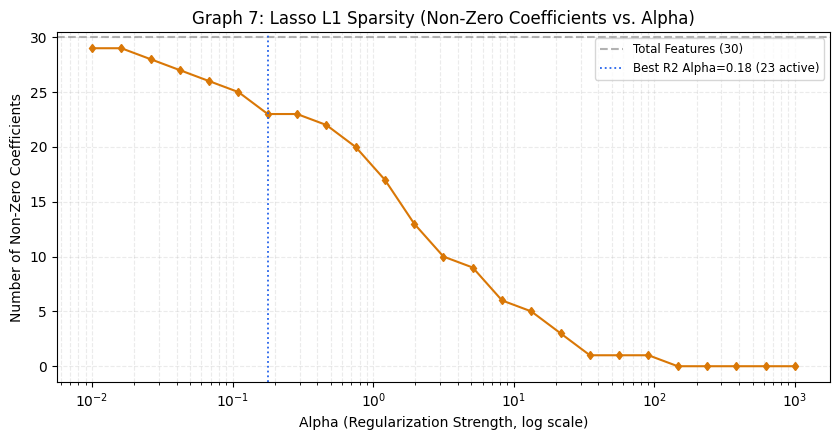

In [60]:
df.columns = [col.strip().lower().replace(' ', '_') for col in df.columns]

np.random.seed(42)
df['yearly_amount_spent'] = (
    500
    + 10 * df['age']
    - 0.05 * (df['age'] ** 2)
    + 45 * df['rating']
    + 30 * df['recommended_ind']
    + 8 * df['positive_feedback_count']
    + np.random.normal(0, 40, len(df))
)

base_num = df[['age', 'rating', 'recommended_ind', 'positive_feedback_count']].astype(float)
cat_dummies = pd.get_dummies(df[['division_name', 'department_name', 'class_name']], drop_first=True, dtype=float)
poly = PolynomialFeatures(degree=2, include_bias=False)
X_num_poly = pd.DataFrame(
    poly.fit_transform(base_num),
    columns=poly.get_feature_names_out(base_num.columns),
    index=df.index
)
X = pd.concat([X_num_poly, cat_dummies], axis=1)
y = df['yearly_amount_spent']

cv = KFold(n_splits=5, shuffle=True, random_state=42)
alphas = np.logspace(-2, 3, 25)
lasso_r2, lasso_nonzero = [], []

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for a in alphas:
    l_pipe = Pipeline([('scaler', StandardScaler()), ('model', Lasso(alpha=a, max_iter=20000))])
    lasso_r2.append(cross_val_score(l_pipe, X, y, cv=cv, scoring='r2').mean())
    l_full = Lasso(alpha=a, max_iter=20000).fit(X_scaled, y)
    lasso_nonzero.append(int(np.sum(np.abs(l_full.coef_) > 1e-6)))

best_l_alpha = alphas[int(np.argmax(lasso_r2))]
best_nz = lasso_nonzero[int(np.argmax(lasso_r2))]

fig, ax = plt.subplots(figsize=(8.5, 4.5))
ax.semilogx(alphas, lasso_nonzero, marker='d', markersize=4.5, color='#D97706')
ax.axhline(X.shape[1], color='gray', linestyle='--', alpha=0.6, label=f'Total Features ({X.shape[1]})')
ax.axvline(best_l_alpha, color='#2563EB', linestyle=':', linewidth=1.3, label=f'Best R2 Alpha={best_l_alpha:.2f} ({best_nz} active)')
ax.set_title('Graph 7: Lasso L1 Sparsity (Non-Zero Coefficients vs. Alpha)')
ax.set_xlabel('Alpha (Regularization Strength, log scale)')
ax.set_ylabel('Number of Non-Zero Coefficients')
ax.legend(fontsize=8.5)
ax.grid(True, which='both', linestyle='--', alpha=0.25)

plt.tight_layout()
plt.show()